# 04 — Bayesian analysis of $\log A$

**What this notebook does**

- builds the Bayesian model $\log A\sim\mathcal N(\mu_g,\sigma_g^2)$ for the 4 groups and samples its posterior with MCMC (`emcee`), with convergence diagnostics (autocorrelation time, $\hat R$);
- derives the posterior of $\Delta=\mu_{nucleus}-\mu_{cytoplasm}$ per line: median, credible intervals (central and HPD), $P(\Delta<0\mid\text{data})$;
- computes the **Bayes factors** for $H_0:\Delta=0$ (exact numerical marginalization) as a function of the prior width on $\Delta$;
- studies the **prior sensitivity** and checks the model with a *posterior predictive check*;
- compares the Gaussian and **Student-$t$** models (WAIC);
- uses a partial-pooling **hierarchical** model for the nucleus–cytoplasm effect across the two lines;
- compares credible and frequentist intervals (notebook 03) at **low statistics**, with toy MC;
- compares the results with those of notebook 03.

**What it does NOT do**

- it does not redo the curve fits (it reads `results/` from notebook 02);
- it does not model the correlation between curves of the same cell (metadata not available): the hierarchical level here is on the *lines*, not on the cells;
- it does not convert $A$ into a Young modulus.

The priors are on $\log A$ (with $A$ in nN/µm$^{3/2}$), a scale where typical values lie in $[-2,1]$: $\mu\sim\mathcal N(0,1^2)$, $\sigma\sim\text{HalfNormal}(1)$ are *weakly informative*. Region labels follow the data folders: `cito` = cytoplasm, `nucleo` = nucleus.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, optimize, special
import emcee, corner
import afm_tools as T

T.set_plot_style()
RNG = np.random.default_rng(20261016)
ana = T.good_sample(T.load_fit_table())
lines = ["MCF7R", "T47DR"]
names = [(l, r) for l in lines for r in ["cito", "nucleo"]]     # parameter order
X = [ana[(ana.cell_line == l) & (ana.region == r)].logA.to_numpy() for l, r in names]
lab = [f"{l} {r}" for l, r in names]
summary = {}
print({k: len(x) for k, x in zip(lab, X)})

{'MCF7R cito': 55, 'MCF7R nucleo': 60, 'T47DR cito': 59, 'T47DR nucleo': 83}


## 1. Base model and MCMC

Parameters $\theta=(\mu_1..\mu_4,\ln\sigma_1..\ln\sigma_4)$. The prior on $\sigma$ is HalfNormal; moving to $\ln\sigma$ introduces the Jacobian $+\ln\sigma$. The function `make_logp` is parametrized by the prior, so that sensitivity checks are straightforward.

In [2]:
def make_logp(mu_sd=1.0, sig_sd=1.0, jeffreys=False):
    def logp(th):
        mu, ls = th[:4], th[4:8]; s = np.exp(ls)
        if np.any(ls < -6) or np.any(ls > 3): return -np.inf
        lp = 0.0 if jeffreys else -0.5 * np.sum(mu ** 2) / mu_sd ** 2        # Jeffreys: flat mu, 1/sigma
        lp += 0.0 if jeffreys else np.sum(-0.5 * (s / sig_sd) ** 2 + ls)
        for x, m, si in zip(X, mu, s):
            lp += -0.5 * np.sum((x - m) ** 2) / si ** 2 - len(x) * np.log(si)
        return lp
    return logp

def rhat(chain):      # chain: (steps, walkers, dim) -> R-hat split over walkers
    n = chain.shape[0] // 2
    ch = np.concatenate([chain[:n], chain[n:2 * n]], axis=1)
    W = ch.var(axis=0, ddof=1).mean(0); B = n * ch.mean(0).var(axis=0, ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)

def run(logp, p0, nwalk=40, nsteps=6000, burn=1500, seed=1):
    ndim = len(p0); rg = np.random.default_rng(seed)
    start = p0 + 1e-2 * rg.standard_normal((nwalk, ndim))
    s = emcee.EnsembleSampler(nwalk, ndim, logp); s.random_state = None
    s.run_mcmc(start, nsteps, progress=False)
    ch = s.get_chain(); tau = s.get_autocorr_time(tol=0)
    return ch[burn:], s.get_log_prob()[burn:], tau

p0 = np.r_[[x.mean() for x in X], np.log([x.std() for x in X])]
chain, lp, tau = run(make_logp(), p0)
flat = chain.reshape(-1, chain.shape[-1])
print("steps per walker:", chain.shape[0], "walkers:", chain.shape[1], " estimated independent samples:", int(flat.shape[0] / tau.max()))
print("tau max:", tau.max().round(1), "  R-hat max:", rhat(chain).max().round(4))
summary["mcmc"] = dict(tau_max=float(tau.max()), rhat_max=float(rhat(chain).max()))

steps per walker: 4500 walkers: 40  estimated independent samples: 1825
tau max: 98.6   R-hat max: 1.0264


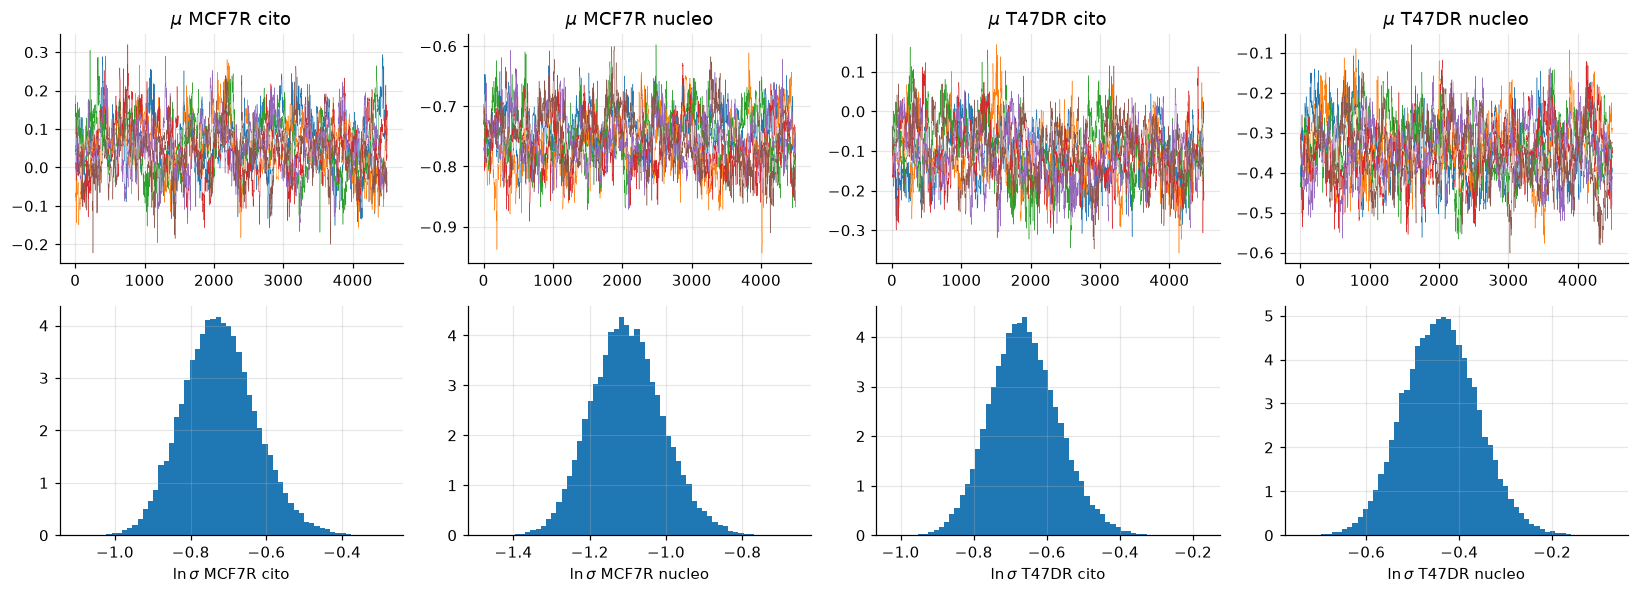

In [3]:
fig, ax = plt.subplots(2, 4, figsize=(15, 5.5), sharex=False)
for k in range(4):
    ax[0, k].plot(chain[:, :6, k], lw=.3); ax[0, k].set_title(f"$\\mu$ {lab[k]}")
    ax[1, k].hist(flat[:, 4 + k] / 1, bins=60, density=True); ax[1, k].set_xlabel(f"$\\ln\\sigma$ {lab[k]}")
plt.tight_layout(); plt.show()

## 2. Posterior of $\Delta=\mu_{nucleus}-\mu_{cytoplasm}$

For each line: median, central 68% and 95% intervals, 95% **HPD** interval (the shortest containing 95% of the mass) and $P(\Delta<0)$. $e^{\Delta}$ is the nucleus/cytoplasm ratio of the typical values of $A$.

In [4]:
def hpd(s, mass=.95):
    s = np.sort(s); n = len(s); k = int(np.floor(mass * n))
    w = s[k:] - s[:n - k]; i = np.argmin(w); return s[i], s[i + k]

def delta_table(flat, label=""):
    out = {}
    for j, l in enumerate(lines):
        d = flat[:, 2 * j + 1] - flat[:, 2 * j]
        lo68, hi68 = np.quantile(d, [.16, .84]); h = hpd(d)
        out[l] = dict(median=np.median(d), lo68=lo68, hi68=hi68, hpd95_lo=h[0], hpd95_hi=h[1], P_neg=(d < 0).mean(),
                      ratio_A=np.exp(np.median(d)))
    return pd.DataFrame(out).T

post = delta_table(flat); summary["delta_posterior"] = post.round(4).to_dict("index"); post.round(4)

,median,lo68,hi68,hpd95_lo,hpd95_hi,P_neg,ratio_A
MCF7R,-0.8121,-0.8882,-0.7350,-0.9654,-0.6575,1.0000,0.4439
T47DR,-0.2450,-0.3425,-0.1443,-0.4333,-0.0454,0.9929,0.7827


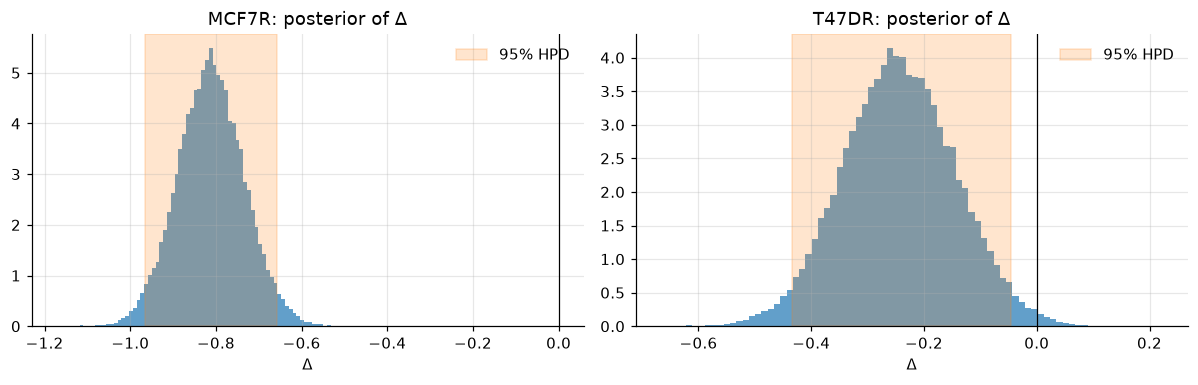

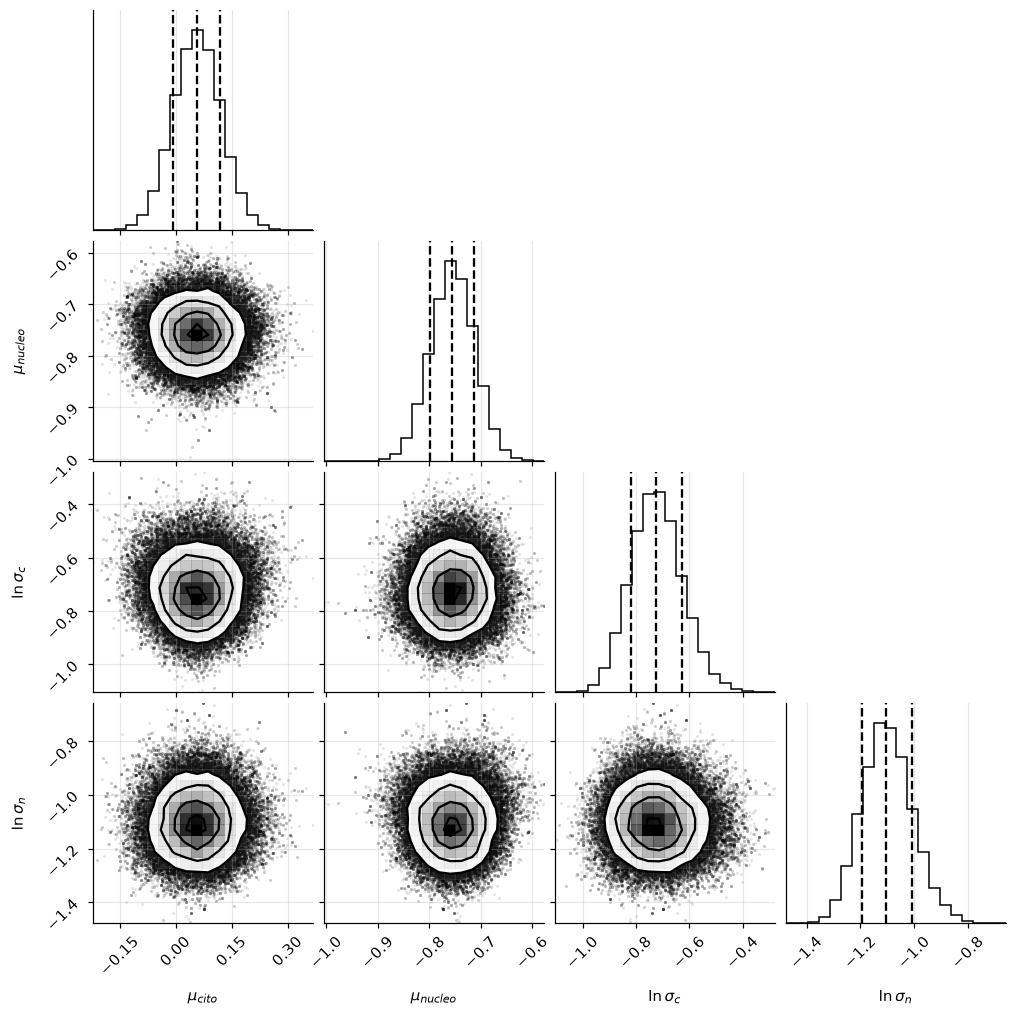

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, (j, l) in zip(ax, enumerate(lines)):
    d = flat[:, 2 * j + 1] - flat[:, 2 * j]
    a.hist(d, bins=80, density=True, alpha=.7); a.axvline(0, c="k", lw=.8)
    a.axvspan(*hpd(d), color="C1", alpha=.2, label="95% HPD"); a.set_title(f"{l}: posterior of $\\Delta$"); a.set_xlabel(r"$\Delta$"); a.legend()
plt.tight_layout(); plt.show()
corner.corner(flat[:, [0, 1, 4, 5]], labels=[r"$\mu_{cito}$", r"$\mu_{nucleo}$", r"$\ln\sigma_c$", r"$\ln\sigma_n$"], quantiles=[.16, .5, .84]); plt.show()

## 3. Bayes factor for $\Delta=0$

For each line we compare $H_1$: $\mu_{nucleo}=\mu_{cito}+\Delta$, $\Delta\sim\mathcal N(0,\tau^2)$ against $H_0$: $\Delta=0$, with $\mu_{cito}\sim\mathcal N(0,1)$ and $p(\sigma)\propto1/\sigma$ common to both models. Marginalizing the $\sigma$ analytically leaves
$$p(\text{data}\mid\mu_c,\Delta)\;\propto\;S_c(\mu_c)^{-n_c/2}\;S_n(\mu_c+\Delta)^{-n_n/2},\qquad S=\sum_i (x_i-\mu)^2,$$
and the integrals over $\mu_c$ and $\Delta$ are done on a grid (no sampling: the method works also for very extreme BFs, where Savage–Dickey with a KDE would fail). The BF depends on the prior width $\tau$ (Lindley paradox): we show it as a function of $\tau$.

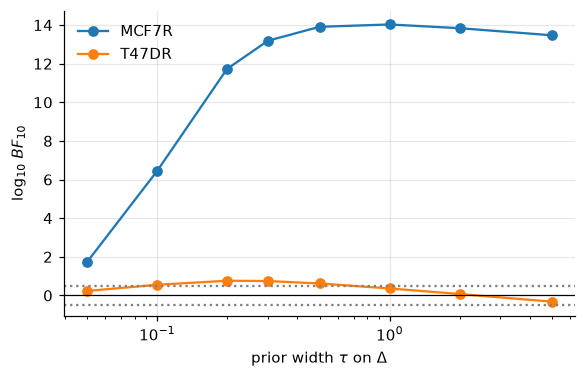

,MCF7R,T47DR
tau_prior_Delta,,
0.05,1.73,0.23
0.10,6.44,0.55
0.20,11.73,0.76
0.30,13.19,0.75
0.50,13.91,0.62
1.00,14.03,0.36
2.00,13.84,0.07
5.00,13.47,-0.32


In [6]:
def log_marg(xc, xn, tau, ngrid=1200):
    # log evidence of H1 (Delta ~ N(0,tau^2)) and of H0 (Delta=0), up to common constants
    nc, nn = len(xc), len(xn)
    mus = np.linspace(xc.mean() - 8 * xc.std() / np.sqrt(nc) - 1, xc.mean() + 8 * xc.std() / np.sqrt(nc) + 1, 900)
    Sc = nc * (xc.var() + (xc.mean() - mus) ** 2)
    def Sn(delta):  # (len(mus), len(delta))
        return nn * (xn.var() + (xn.mean() - mus[:, None] - delta[None, :]) ** 2)
    lp_mu = stats.norm.logpdf(mus, 0, 1)
    ll0 = -nc / 2 * np.log(Sc) - nn / 2 * np.log(Sn(np.zeros(1))[:, 0]) + lp_mu
    dels = np.linspace(-6 * max(tau, .05) - 1.5, 6 * max(tau, .05) + 1.5, ngrid)
    dels = np.unique(np.r_[dels, np.linspace(xn.mean() - xc.mean() - .6, xn.mean() - xc.mean() + .6, 400)])
    ll1 = (-nc / 2 * np.log(Sc))[:, None] - nn / 2 * np.log(Sn(dels)) + lp_mu[:, None] + stats.norm.logpdf(dels, 0, tau)[None, :]
    e0 = special.logsumexp(ll0) + np.log(mus[1] - mus[0])
    # 2D integration with trapezoids on a non-uniform Delta grid
    inner = special.logsumexp(ll1, axis=0) + np.log(mus[1] - mus[0])
    e1 = np.log(np.trapezoid(np.exp(inner - inner.max()), dels)) + inner.max()
    return e1, e0

taus = np.array([.05, .1, .2, .3, .5, 1, 2, 5])
bf = {l: [] for l in lines}
for l, (xc, xn) in zip(lines, [(X[0], X[1]), (X[2], X[3])]):
    for t in taus:
        e1, e0 = log_marg(xc, xn, t); bf[l].append((e1 - e0) / np.log(10))      # log10 BF_10
bf = pd.DataFrame(bf, index=taus); bf.index.name = "tau_prior_Delta"
summary["log10_BF10"] = bf.round(2).to_dict()
fig, ax = plt.subplots(figsize=(6, 3.6)); ax.plot(bf.index, bf, "o-"); ax.legend(lines)
ax.axhline(0, c="k", lw=.8); ax.axhline(np.log10(3), ls=":", c="gray"); ax.axhline(-np.log10(3), ls=":", c="gray")
ax.set_xscale("log"); ax.set_xlabel(r"prior width $\tau$ on $\Delta$"); ax.set_ylabel(r"$\log_{10}\,BF_{10}$"); plt.show()
bf.round(2)

$\log_{10}BF_{10}>2$ is decisive evidence (Jeffreys scale) in favour of $\Delta\neq0$. For MCF7R the evidence is overwhelming for any $\tau\gtrsim0.2$. For T47DR instead $\log_{10}BF_{10}\lesssim0.8$ (at most ~6:1) and it becomes negative for very wide priors: **weak** evidence even with $p\approx0.01$ in the frequentist test. This is the classic case where p-value and Bayes factor give different verdicts (the BF penalizes the spread of the prior on $\Delta$ under $H_1$).

## 4. Prior sensitivity

We repeat the sampling with very wide and narrow priors and with the Jeffreys prior (flat on $\mu$, $1/\sigma$) and compare the posterior of $\Delta$.

In [7]:
priors = {"nominal N(0,1)/HN(1)": dict(), "wide N(0,10)/HN(10)": dict(mu_sd=10, sig_sd=10),
          "narrow N(0,0.3)/HN(0.5)": dict(mu_sd=.3, sig_sd=.5), "Jeffreys": dict(jeffreys=True)}
rows = []
for nm, kw in priors.items():
    ch, _, _ = run(make_logp(**kw), p0, nsteps=4000, burn=1000, seed=7)
    t = delta_table(ch.reshape(-1, 8))
    for l in lines: rows.append(dict(prior=nm, line=l, median=t.loc[l, "median"], lo68=t.loc[l, "lo68"], hi68=t.loc[l, "hi68"], P_neg=t.loc[l, "P_neg"]))
sens = pd.DataFrame(rows); summary["prior_sensitivity"] = sens.round(4).to_dict("records"); sens.round(4)

,prior,line,median,lo68,hi68,P_neg
0,"nominal N(0,1)/HN(1)",MCF7R,-0.8123,-0.8898,-0.7351,1.0000
1,"nominal N(0,1)/HN(1)",T47DR,-0.2466,-0.3443,-0.1484,0.9942
2,"wide N(0,10)/HN(10)",MCF7R,-0.8165,-0.8931,-0.7415,1.0000
3,"wide N(0,10)/HN(10)",T47DR,-0.2419,-0.3416,-0.1447,0.9926
4,"narrow N(0,0.3)/HN(0.5)",MCF7R,-0.7917,-0.8698,-0.7174,1.0000
5,"narrow N(0,0.3)/HN(0.5)",T47DR,-0.2365,-0.3324,-0.1426,0.9935
6,Jeffreys,MCF7R,-0.8129,-0.8884,-0.7371,1.0000
7,Jeffreys,T47DR,-0.2465,-0.3440,-0.1497,0.9937


## 5. Posterior predictive check

From the posterior we simulate replicated datasets and compare observed and simulated statistics (mean, standard deviation, skewness): an observed value in the tails of the predictive distribution signals that the Gaussian model does not describe that feature well.

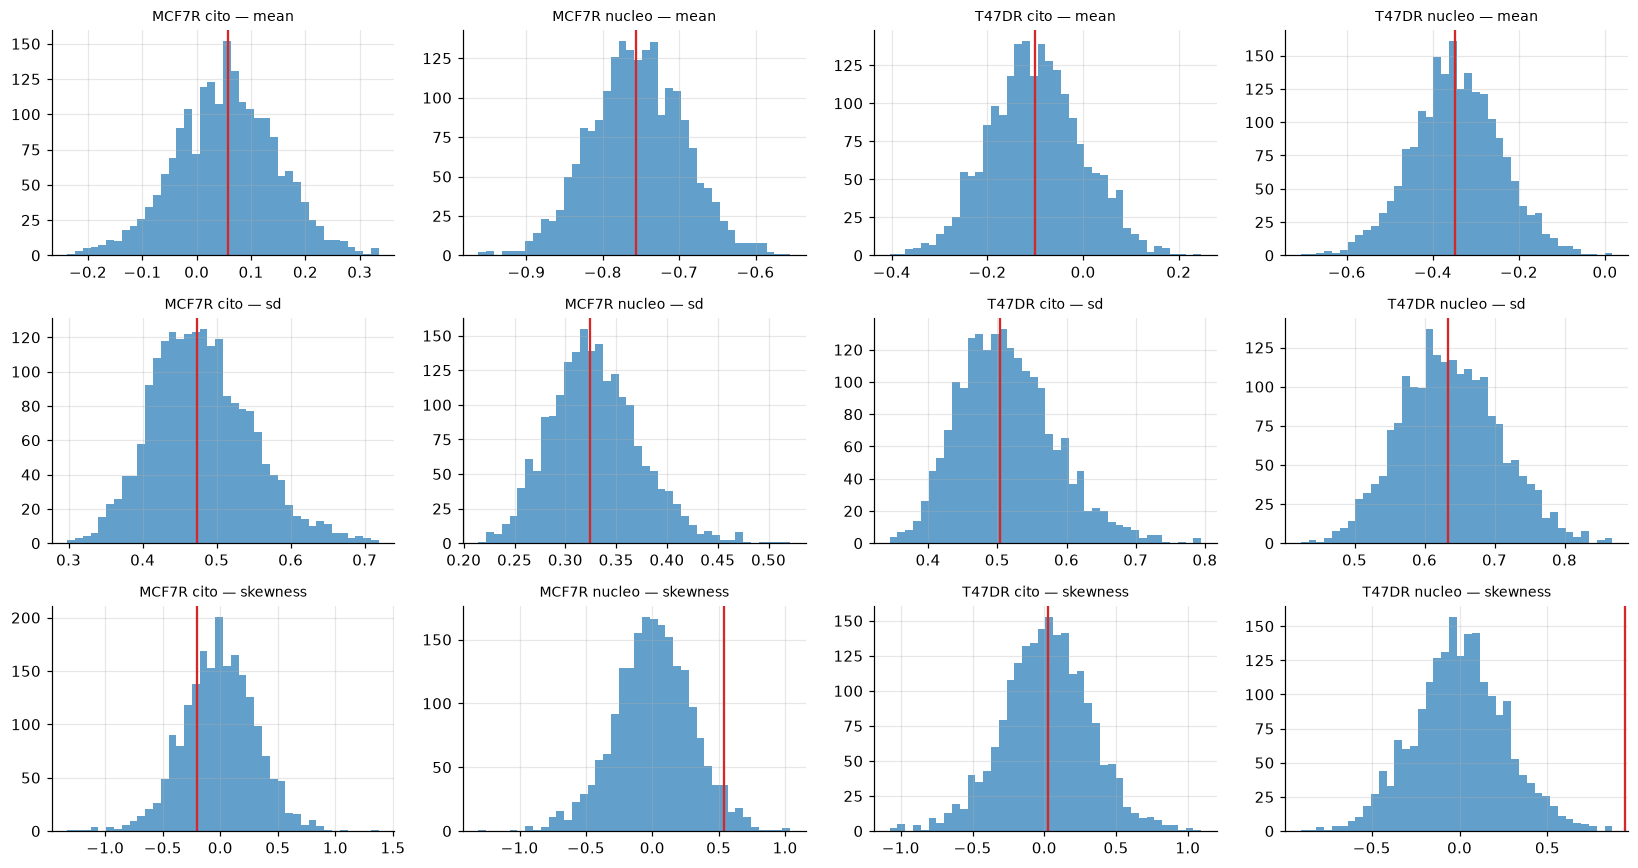

{'MCF7R cito|mean': 0.488, 'MCF7R cito|sd': 0.508, 'MCF7R cito|skewness': 0.747, 'MCF7R nucleo|mean': 0.508, 'MCF7R nucleo|sd': 0.524, 'MCF7R nucleo|skewness': 0.036, 'T47DR cito|mean': 0.506, 'T47DR cito|sd': 0.524, 'T47DR cito|skewness': 0.488, 'T47DR nucleo|mean': 0.505, 'T47DR nucleo|sd': 0.502, 'T47DR nucleo|skewness': 0.0}


In [8]:
sel = RNG.choice(len(flat), 2000, replace=False)
fig, ax = plt.subplots(3, 4, figsize=(15, 8)); ppp = {}
for k, x in enumerate(X):
    rep = [RNG.normal(flat[i, k], np.exp(flat[i, 4 + k]), len(x)) for i in sel]
    for r_, (nm, f_) in enumerate([("mean", np.mean), ("sd", np.std), ("skewness", stats.skew)]):
        sim = np.array([f_(y) for y in rep]); obs = f_(x); ax[r_, k].hist(sim, bins=40, alpha=.7); ax[r_, k].axvline(obs, c="C3")
        ax[r_, k].set_title(f"{lab[k]} — {nm}", fontsize=9); ppp[f"{lab[k]}|{nm}"] = float((sim > obs).mean())
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in ppp.items()}); summary["ppc_pvalues"] = ppp

## 6. Gaussian versus Student-$t$ (WAIC)

The Student-$t$ likelihood (free degrees of freedom $\nu$, exponential prior on $\nu-1$ with mean 30) tolerates heavier tails. Comparison with the WAIC (higher $\text{elpd}$ = better).

In [9]:
def make_logp_t():
    def logp(th):
        mu, ls, nu = th[:4], th[4:8], th[8]
        if np.any(ls < -6) or np.any(ls > 3) or not (1.0 < nu < 200): return -np.inf
        s = np.exp(ls); lp = -0.5 * np.sum(mu ** 2) + np.sum(-0.5 * s ** 2 + ls) - (nu - 1) / 30
        for x, m, si in zip(X, mu, s): lp += np.sum(stats.t.logpdf(x, nu, m, si))
        return lp
    return logp

ch_t, _, tau_t = run(make_logp_t(), np.r_[p0, 20.0], nsteps=6000, burn=1500, seed=3)
flat_t = ch_t.reshape(-1, 9)
print("nu median:", np.median(flat_t[:, 8]).round(1), " [16,84]%:", np.quantile(flat_t[:, 8], [.16, .84]).round(1), "  rhat max:", rhat(ch_t).max().round(3))

def waic(logpt):    # logpt: (samples, observations)
    lppd = special.logsumexp(logpt, axis=0) - np.log(logpt.shape[0]); pw = logpt.var(axis=0)
    return (lppd - pw).sum(), pw.sum()

xs_all = np.concatenate(X); gid = np.concatenate([np.full(len(x), k) for k, x in enumerate(X)]); ss = RNG.choice(len(flat), 1500, replace=False)
ll_g = np.array([stats.norm.logpdf(xs_all, flat[i, gid], np.exp(flat[i, 4 + gid])) for i in ss])
ll_t = np.array([stats.t.logpdf(xs_all, flat_t[i, 8], flat_t[i, gid], np.exp(flat_t[i, 4 + gid])) for i in ss])
(w_g, pg), (w_t, pt) = waic(ll_g), waic(ll_t)
print(f"elpd_WAIC  Gaussian: {w_g:.1f} (p_eff {pg:.1f})   Student-t: {w_t:.1f} (p_eff {pt:.1f})   difference t - Gauss: {w_t - w_g:.1f}")
t_post = delta_table(flat_t[:, :8]); summary["waic"] = dict(gauss=float(w_g), student_t=float(w_t), nu_median=float(np.median(flat_t[:, 8])))
summary["delta_posterior_student_t"] = t_post.round(4).to_dict("index"); t_post.round(4)

nu median: 39.1  [16,84]%: [19.4 76.6]   rhat max: 1.034


elpd_WAIC  Gaussian: -185.5 (p_eff 7.3)   Student-t: -185.9 (p_eff 7.2)   difference t - Gauss: -0.4


,median,lo68,hi68,hpd95_lo,hpd95_hi,P_neg,ratio_A
MCF7R,-0.8226,-0.9016,-0.7439,-0.9775,-0.6637,1.0000,0.4393
T47DR,-0.2611,-0.3571,-0.1657,-0.4516,-0.0736,0.9962,0.7702


## 7. Hierarchical model: nucleus–cytoplasm effect across lines

If the nucleus effect is a phenomenon common to both tumours, it makes sense to share information between the lines (*partial pooling*):
$$\mu_{l,cito}=a_l,\qquad \mu_{l,nucleo}=a_l+b+u_l,\qquad u_l\sim\mathcal N(0,\tau_u^2),\quad\tau_u\sim\text{HalfNormal}(0.5),$$
with $b$ the common effect and $u_l$ the line-specific deviation. $\tau_u\to0$ is the «identical effect» model, $\tau_u\to\infty$ independent lines. The posterior of $\tau_u$ measures how much the data support a different effect between the lines (Bayesian analogue of the interaction test of notebook 03).

In [10]:
def logp_h(th):
    a, b, u, ltu, ls = th[0:2], th[2], th[3:5], th[5], th[6:10]
    tu = np.exp(ltu)
    if np.any(ls < -6) or np.any(ls > 3) or not (-6 < ltu < 3): return -np.inf
    s = np.exp(ls)
    lp = -0.5 * np.sum(a ** 2) - 0.5 * b ** 2 + np.sum(stats.norm.logpdf(u, 0, tu)) - 0.5 * (tu / .5) ** 2 + ltu + np.sum(-0.5 * s ** 2 + ls)
    mus = [a[0], a[0] + b + u[0], a[1], a[1] + b + u[1]]
    for x, m, si in zip(X, mus, s): lp += -0.5 * np.sum((x - m) ** 2) / si ** 2 - len(x) * np.log(si)
    return lp

ph0 = np.r_[X[0].mean(), X[2].mean(), -0.5, 0, 0, np.log(.3), np.log([x.std() for x in X])]
ch_h, _, tau_h = run(logp_h, ph0, nwalk=50, nsteps=8000, burn=2500, seed=5)
fh = ch_h.reshape(-1, 10)
print("R-hat max:", rhat(ch_h).max().round(3), " tau max:", tau_h.max().round(0))
d_h = {"b (common)": fh[:, 2], "b+u_MCF7R": fh[:, 2] + fh[:, 3], "b+u_T47DR": fh[:, 2] + fh[:, 4], "tau_u": np.exp(fh[:, 5])}
hier = pd.DataFrame({k: dict(median=np.median(v), lo68=np.quantile(v, .16), hi68=np.quantile(v, .84)) for k, v in d_h.items()}).T
summary["hierarchical"] = hier.round(4).to_dict("index"); hier.round(4)

R-hat max: 1.03  tau max: 123.0


,median,lo68,hi68
b (common),-0.4884,-0.7688,-0.1642
b+u_MCF7R,-0.7995,-0.8785,-0.7185
b+u_T47DR,-0.2666,-0.3648,-0.1691
tau_u,0.4293,0.2569,0.7050


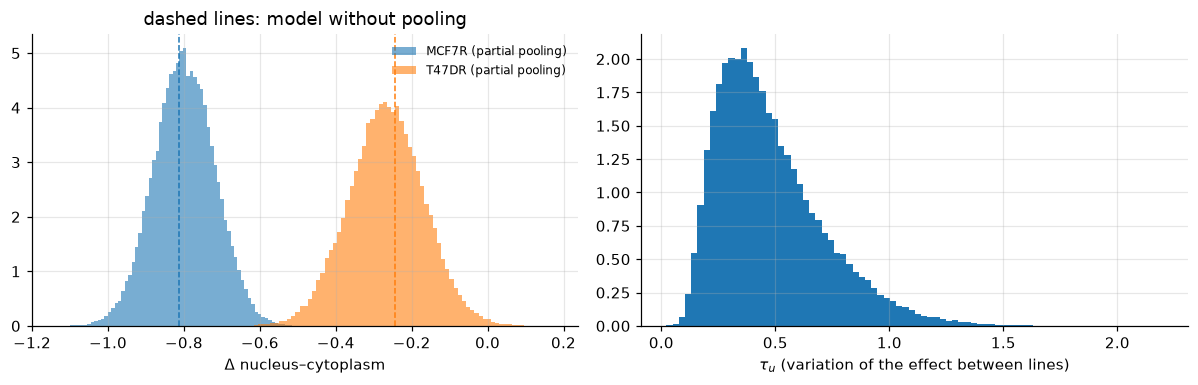

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(d_h["b+u_MCF7R"], bins=80, alpha=.6, density=True, label="MCF7R (partial pooling)"); ax[0].hist(d_h["b+u_T47DR"], bins=80, alpha=.6, density=True, label="T47DR (partial pooling)")
for j, l in enumerate(lines): ax[0].axvline(post.loc[l, "median"], ls="--", c=f"C{j}", lw=1)
ax[0].set_xlabel(r"$\Delta$ nucleus–cytoplasm"); ax[0].legend(fontsize=8); ax[0].set_title("dashed lines: model without pooling")
ax[1].hist(d_h["tau_u"], bins=80, density=True); ax[1].set_xlabel(r"$\tau_u$ (variation of the effect between lines)")
plt.tight_layout(); plt.show()

## 8. Low statistics: credible versus frequentist intervals

When the number of curves is small (few measured cells) the two approaches can give different answers. With the real curves as generating population ($\mu_c$, $\sigma_c$, $\sigma_n$ of T47DR, $\Delta=\Delta_{T47DR}$) we simulate experiments with $n=5,\dots,80$ curves per group and compare **coverage** and **length** of: the 68% credible interval (flat prior on $\mu$, $1/\sigma$; exact grid posterior) and the 68% profile-likelihood interval (notebook 03).

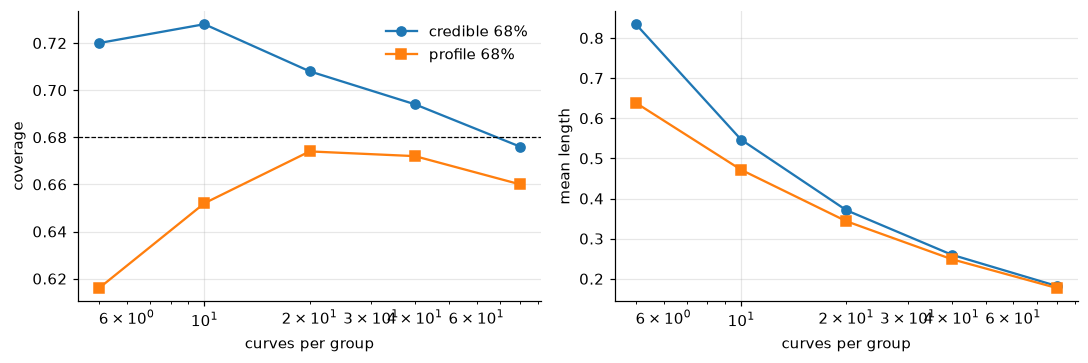

,coverage_credible,coverage_profile,length_credible,length_profile
n_per_group,,,,
5,0.720,0.616,0.834,0.638
10,0.728,0.652,0.547,0.472
20,0.708,0.674,0.371,0.343
40,0.694,0.672,0.260,0.249
80,0.676,0.660,0.182,0.177


In [12]:
def intervals(xc, xn, ngrid=(300, 400)):
    nc, nn = len(xc), len(xn); d_hat = xn.mean() - xc.mean(); s = np.hypot(xc.std() / np.sqrt(nc), xn.std() / np.sqrt(nn)) + 1e-9
    dels = np.linspace(d_hat - 8 * s, d_hat + 8 * s, ngrid[1])
    mus = np.linspace(xc.mean() - 8 * xc.std() / np.sqrt(nc), xc.mean() + 8 * xc.std() / np.sqrt(nc), ngrid[0])
    Sc = nc * (xc.var() + (xc.mean() - mus) ** 2)
    Sn = nn * (xn.var() + (xn.mean() - mus[:, None] - dels[None, :]) ** 2)
    ll = -nc / 2 * np.log(Sc)[:, None] - nn / 2 * np.log(Sn)           # joint posterior (mu_c, Delta), prior 1/sigma
    post = np.exp(special.logsumexp(ll, axis=0) - ll.max()); cdf = np.cumsum(post); cdf /= cdf[-1]
    cred = (np.interp(.16, cdf, dels), np.interp(.84, cdf, dels))
    prof = nc * np.log(Sc[:, None] / nc) + nn * np.log(Sn / nn); p = prof.min(0); ok = dels[p - p.min() <= 1]
    return cred, (ok.min(), ok.max())

xc0, xn0 = X[2], X[3]; mc, sc, mn, sn = xc0.mean(), xc0.std(), xn0.mean(), xn0.std(); d_true = mn - mc
rows = []
for n in [5, 10, 20, 40, 80]:
    cov_b = cov_f = len_b = len_f = 0; N = 500
    for _ in range(N):
        xc = RNG.normal(mc, sc, n); xn = RNG.normal(mc + d_true, sn, n); (b0, b1), (f0, f1) = intervals(xc, xn)
        cov_b += b0 <= d_true <= b1; cov_f += f0 <= d_true <= f1; len_b += b1 - b0; len_f += f1 - f0
    rows.append(dict(n_per_group=n, coverage_credible=cov_b / N, coverage_profile=cov_f / N, length_credible=len_b / N, length_profile=len_f / N))
low = pd.DataFrame(rows).set_index("n_per_group"); summary["low_statistics"] = low.round(4).to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(low.index, low.coverage_credible, "o-", label="credible 68%"); ax[0].plot(low.index, low.coverage_profile, "s-", label="profile 68%")
ax[0].axhline(.68, c="k", ls="--", lw=.8); ax[0].set_xscale("log"); ax[0].set_xlabel("curves per group"); ax[0].set_ylabel("coverage"); ax[0].legend()
ax[1].plot(low.index, low.length_credible, "o-"); ax[1].plot(low.index, low.length_profile, "s-"); ax[1].set_xscale("log"); ax[1].set_xlabel("curves per group"); ax[1].set_ylabel("mean length")
plt.tight_layout(); plt.show(); low.round(3)

## 9. Comparison with the frequentist analysis (notebook 03)

In [13]:
f3 = json.load(open(T.RESULTS_DIR / "03_summary.json"))
rows = []
for l in lines:
    d3 = f3["nucleus_vs_cito"][l]["delta_mean"]
    rows.append(dict(line=l, freq_delta=d3, bayes_median=post.loc[l, "median"], bayes_lo68=post.loc[l, "lo68"], bayes_hi68=post.loc[l, "hi68"],
                     p_wilks=f3["nucleus_vs_cito"][l]["p_wilks"], P_bayes_Delta_ge_0=1 - post.loc[l, "P_neg"], log10_BF_tau05=bf.loc[.5, l],
                     Delta_hierarchical=np.median(d_h["b+u_" + l])))
comp = pd.DataFrame(rows).set_index("line"); summary["comparison_with_nb03"] = comp.round(5).to_dict("index"); comp.round(4)

,freq_delta,bayes_median,bayes_lo68,bayes_hi68,p_wilks,P_bayes_Delta_ge_0,log10_BF_tau05,Delta_hierarchical
line,,,,,,,,
MCF7R,-0.8139,-0.8121,-0.8882,-0.7350,0.0000,0.0000,13.9077,-0.7995
T47DR,-0.2468,-0.2450,-0.3425,-0.1443,0.0107,0.0071,0.6203,-0.2666


In [14]:
json.dump(summary, open(T.RESULTS_DIR / "04_summary.json", "w"), indent=1, default=float)

## Interpretation and limits

- Frequentists and Bayesians agree on sign and size of $\Delta$ for both lines (weak priors, $n\sim50$–$80$ per group): the nucleus is softer than the cytoplasm. For MCF7R the evidence is overwhelming; for T47DR the credible interval excludes zero but the Bayes factor is only ~4:1 and depends on the prior on $\Delta$: the effect should be considered *indicative*, not established.
- The hierarchical model slightly reduces the difference between the two lines without cancelling it: the interaction remains the qualitatively most interesting result, but it must be read with the caveats of notebook 03 (same session for the two regions, different sessions for the two lines).
- The Student-$t$ does not improve the WAIC ($\nu\approx38$): the tails are not the problem. The posterior predictive check shows instead an **asymmetry** not reproduced by the Gaussian model in the *nucleus* groups (especially T47DR nucleus, $p_{PPC}\approx0$): the distribution of $\log A$ in the nucleus has a tail towards high values (possible mixture of subpopulations or measurement points). Mean and sd are well reproduced, so the estimates of $\Delta$ remain reasonable, but a mixture model would be the next step (notebook 05).
- At low statistics credible and profile intervals cover similarly; systematic differences in coverage/length appear mainly for $n\lesssim10$.
- The caveats on **pseudo-replication** still hold: without the cell identifier the intervals are optimistic.

## Output produced and next step

```text
results/04_summary.json   posterior of Δ, BF, prior sensitivity, PPC, WAIC, hierarchical, low statistics, comparison with notebook 03
```

Next: `05_ml_curve_analysis.ipynb` — anomaly detection on the curves and classification of cytoplasm/nucleus and MCF7R/T47DR with physical features.